In [10]:
import os
import pandas as pd
from google.cloud import bigquery

# THIS is the magic line that fixes the Anaconda error
os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = "/Users/tushaarkapil/.config/gcloud/application_default_credentials.json"

# Initialize the BigQuery client
client = bigquery.Client(project="alpine-avatar-510515-j2")

# The optimized time-series query
query = """
SELECT 
  PARSE_DATE('%Y%m%d', event_date) AS date,
  COUNT(DISTINCT user_pseudo_id) AS daily_visitors,
  COUNT(DISTINCT IF(event_name = 'purchase', user_pseudo_id, NULL)) AS daily_purchasers
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
GROUP BY date
ORDER BY date ASC;
"""


/opt/anaconda3/lib/python3.13/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


In [11]:

# Execute the query and load directly into a Pandas DataFrame
df_daily = client.query(query).to_dataframe()
df_daily['date'] = pd.to_datetime(df_daily['date'])

print(df_daily.head())

/opt/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


        date  daily_visitors  daily_purchasers
0 2020-11-01            2365                13
1 2020-11-02            3262                39
2 2020-11-03            4648                46
3 2020-11-04            3734                30
4 2020-11-05            3272                26


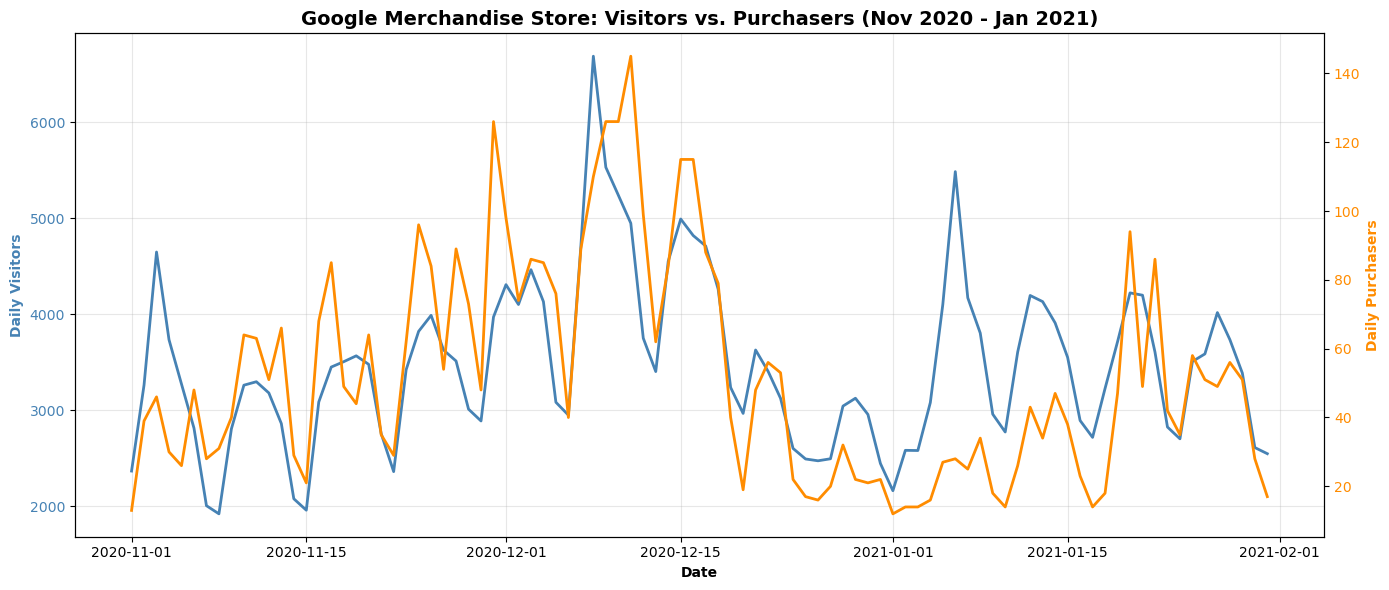

In [12]:
import matplotlib.pyplot as plt

# Set up the figure and axis
fig, ax1 = plt.subplots(figsize=(14, 6))

# Plot Daily Visitors on the primary Y-axis
ax1.plot(df_daily['date'], df_daily['daily_visitors'], color='steelblue', linewidth=2, label='Visitors')
ax1.set_xlabel('Date', fontweight='bold')
ax1.set_ylabel('Daily Visitors', color='steelblue', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.grid(alpha=0.3)

# Create a secondary Y-axis for Daily Purchasers
ax2 = ax1.twinx()  
ax2.plot(df_daily['date'], df_daily['daily_purchasers'], color='darkorange', linewidth=2, label='Purchasers')
ax2.set_ylabel('Daily Purchasers', color='darkorange', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='darkorange')

# Add a title
plt.title('Google Merchandise Store: Visitors vs. Purchasers (Nov 2020 - Jan 2021)', fontsize=14, fontweight='bold')

# Show the plot
fig.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


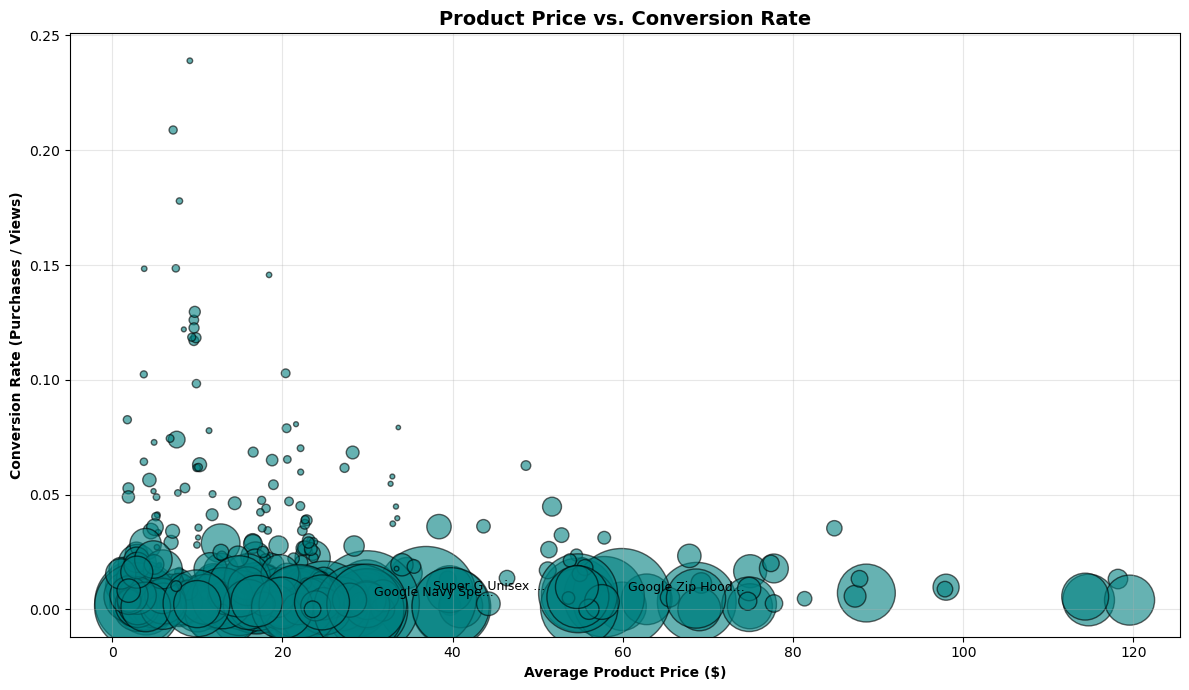

In [ ]:

# 1. Query the product data
query_products = """
WITH product_stats AS (
  SELECT 
    item.item_name,
    AVG(item.price) AS avg_price,
    SUM(CASE WHEN event_name = 'view_item' THEN 1 ELSE 0 END) AS total_views,
    SUM(CASE WHEN event_name = 'purchase' THEN 1 ELSE 0 END) AS total_purchases
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`,
  UNNEST(items) AS item 
  GROUP BY item.item_name
)
SELECT 
  item_name,
  avg_price,
  total_views,
  total_purchases,
  SAFE_DIVIDE(total_purchases, total_views) AS conversion_rate
FROM product_stats
WHERE total_views > 100 -- Filter out statistical noise
"""

# 2. Load into DataFrame
df_products = client.query(query_products).to_dataframe()

# Drop any rows where price or conversion rate is missing
df_products = df_products.dropna(subset=['avg_price', 'conversion_rate'])

# 3. Build the Scatter Plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot the points (dot size represents total views)
scatter = ax.scatter(
    df_products['avg_price'], 
    df_products['conversion_rate'], 
    s=df_products['total_views'] / 10, # Scale down the bubble size for readability
    alpha=0.6, 
    c='teal',
    edgecolors='black'
)

ax.set_title('Product Price vs. Conversion Rate', fontsize=14, fontweight='bold')
ax.set_xlabel('Average Product Price ($)', fontweight='bold')
ax.set_ylabel('Conversion Rate (Purchases / Views)', fontweight='bold')
ax.grid(alpha=0.3)

# Highlight a few top-viewed products
top_products = df_products.nlargest(3, 'total_views')
for _, row in top_products.iterrows():
    ax.annotate(row['item_name'][:15] + '...', 
                (row['avg_price'], row['conversion_rate']),
                xytext=(5, 5), textcoords='offset points', fontsize=9)

fig.tight_layout()
plt.show()